# 国别样本分布分析

## 分析目标
统计国别覆盖、错句与作文规模、样本集中程度及候选国家（仅探索性分析，不修改源数据）

## 1. 环境配置与数据读取

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/interim/errors_merged.csv').exists()), None)
if root is None:
    raise FileNotFoundError('请从HSK项目目录或其子目录运行Notebook')
output = root / 'reports/exploration/country_distribution'
output.mkdir(parents=True, exist_ok=True)
fonts = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ['PingFang SC', 'Heiti SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'SimHei'] if f in fonts), None)
if font:
    plt.rcParams['font.sans-serif'] = [font]
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

df = pd.read_csv(root / 'data/interim/errors_merged.csv', dtype={'国籍': 'string', '作文编码': 'string'})
print(f'原始记录数：{len(df):,}；字段数：{df.shape[1]}')
display(df.head(3))

原始记录数：155,643；字段数：16


,record_id,作文编码,国籍,性别,考试时间,作文题目,口试分数,作文分数,听力分数,阅读分数,综合分数,总分,证书,检索原句,source_file,source_row
0,1,200509534533250032,新加坡,女,200509,一封求职信,85.0,75.0,91,84,95,422,A,相信这一点长处能让我为快乐家庭旅游公司{CD的导游一职}做出更多贡献。,A.csv,2
1,2,200410534533250066,新加坡,女,200410,最理想的结交方式,90.0,85.0,83,70,96,421,A,这为结婚后俩人的生活{CC和观点}[BD，]打[C]下{CQ了}深厚的基础。,A.csv,3
2,3,200103533540150013,印度尼西亚,男,200103,我对离婚问题的看法,80.0,90.0,85,82,92,424,A,我认为婚姻是一辈子的承诺，是对自己、配偶、家庭所要履行的一种责任。,A.csv,4


## 2. 国别字段基础核验
仅在分析副本中去除首尾空格，将空字符串视为缺失；检查同一作文是否对应多个国籍；不自动合并国别名称。

In [4]:
country, essay = '国籍', '作文编码'
work = df.copy()
for col in [country, essay]:
    work[col] = work[col].str.strip().replace('', pd.NA)
valid = work.dropna(subset=[country, essay]).copy()
conflicts = valid.groupby(essay)[country].nunique().loc[lambda s: s > 1]
print('国籍缺失记录：', work[country].isna().sum())
print('作文编码缺失记录：', work[essay].isna().sum())
print('国籍冲突作文：', len(conflicts))
print('完整行重复（不含首次）：', df.duplicated().sum())
display(work[country].value_counts(dropna=False).to_frame('记录数'))
if not conflicts.empty:
    display(valid.loc[valid[essay].isin(conflicts.index), [essay, country]].drop_duplicates().head(30))
# 排除国籍冲突作文，仅用于本轮统计，不修改源文件
sample = valid.loc[~valid[essay].isin(conflicts.index)].copy()
print(f'纳入记录：{len(sample):,}；排除记录：{len(df)-len(sample):,}')
assert len(sample) > 0, '无有效样本' 

国籍缺失记录： 19
作文编码缺失记录： 0
国籍冲突作文： 0
完整行重复（不含首次）： 0


,记录数
国籍,
韩国,59670
日本,46967
新加坡,11126
印度尼西亚,8545
马来西亚,5892
...,...
墨西哥,8
贝宁,7
刚果,5


纳入记录：155,624；排除记录：19


## 3. 国别样本数量统计
以有效错句记录和独立作文为两个统计单位。占比的分母为纳入样本。

In [5]:
stats = sample.groupby(country).agg(错句记录数=(essay, 'size'), 作文数=(essay, 'nunique'))
stats = stats.sort_values(['作文数', '错句记录数'], ascending=False)
stats['错句占比'] = stats['错句记录数'] / stats['错句记录数'].sum()
stats['作文占比'] = stats['作文数'] / stats['作文数'].sum()
stats['篇均错句记录数'] = stats['错句记录数'] / stats['作文数']
stats['作文累计占比'] = stats['作文占比'].cumsum()
assert stats['作文数'].sum() == sample[essay].nunique()
print(f'国别字段不同取值：{len(stats)}；独立作文：{sample[essay].nunique():,}')
display(stats.head(20).style.format({'错句占比':'{:.2%}', '作文占比':'{:.2%}', '作文累计占比':'{:.2%}', '篇均错句记录数':'{:.2f}'}))

国别字段不同取值：101；独立作文：11,333


,错句记录数,作文数,错句占比,作文占比,篇均错句记录数,作文累计占比
国籍,,,,,,
韩国,59670,4169,38.34%,36.79%,14.31,36.79%
日本,46967,3211,30.18%,28.33%,14.63,65.12%
新加坡,11126,843,7.15%,7.44%,13.20,72.56%
印度尼西亚,8545,739,5.49%,6.52%,11.56,79.08%
马来西亚,5892,422,3.79%,3.72%,13.96,82.80%
泰国,3979,374,2.56%,3.30%,10.64,86.10%
越南,2541,221,1.63%,1.95%,11.50,88.05%
缅甸,2436,202,1.57%,1.78%,12.06,89.83%
澳大利亚,1648,123,1.06%,1.09%,13.40,90.92%


## 4. 国别样本分布可视化
分别按作文数和错句记录数排名

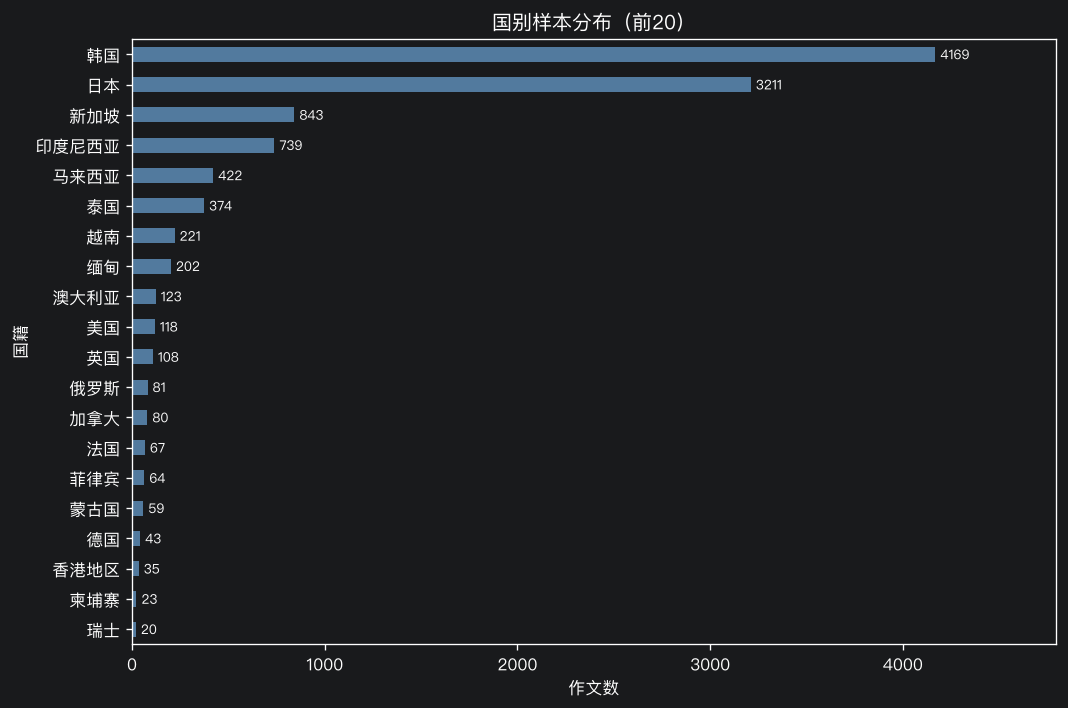

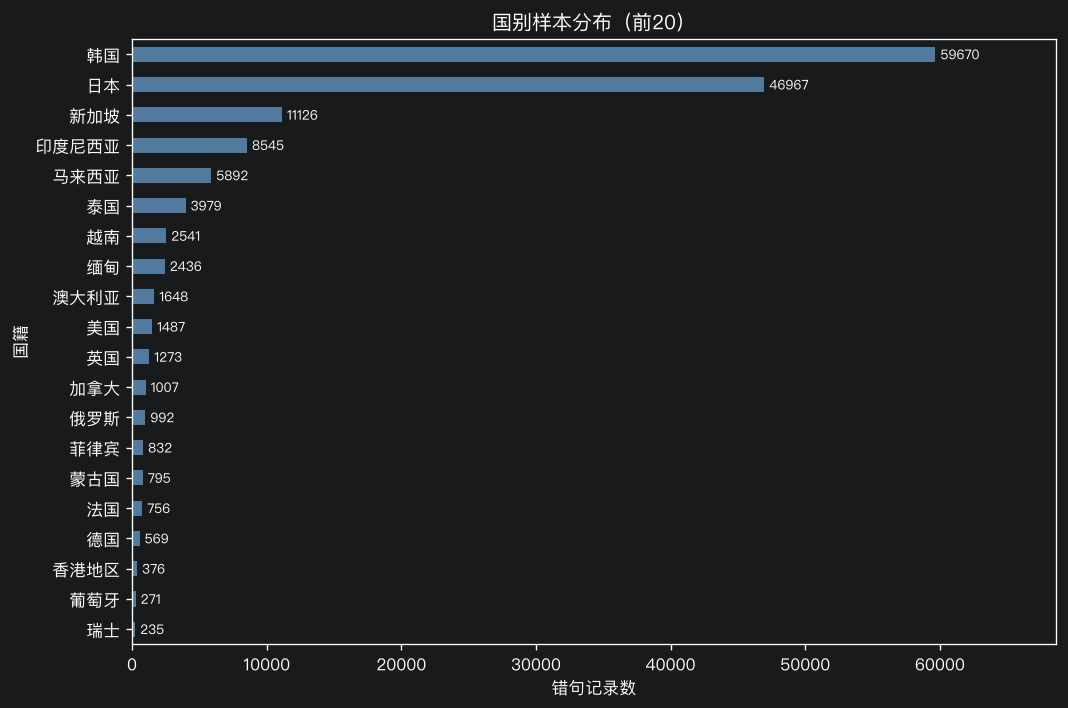

In [6]:
TOP_N = 20
for col, filename in [('作文数', 'top_essay_counts.png'), ('错句记录数', 'top_error_counts.png')]:
    top = stats[col].nlargest(TOP_N).sort_values()
    ax = top.plot.barh(figsize=(9, 6), color='#527a9e')
    ax.set(xlabel=col, ylabel='国籍', title=f'国别样本分布（前{len(top)}）')
    ax.bar_label(ax.containers[0], padding=3, fontsize=8)
    ax.margins(x=0.15)
    plt.tight_layout()
    plt.savefig(output / filename, bbox_inches='tight', dpi=160)
    plt.show()

## 5. 样本集中度与长尾分析
以作文数排序，计算头部国家累计占比及达到指定覆盖比例所需的国家数量。

前3个国别作文占比：72.56%
前5个国别作文占比：82.80%
前10个国别作文占比：91.96%
前20个国别作文占比：97.08%
覆盖50%作文需要 2 个国别
覆盖80%作文需要 5 个国别
覆盖90%作文需要 9 个国别


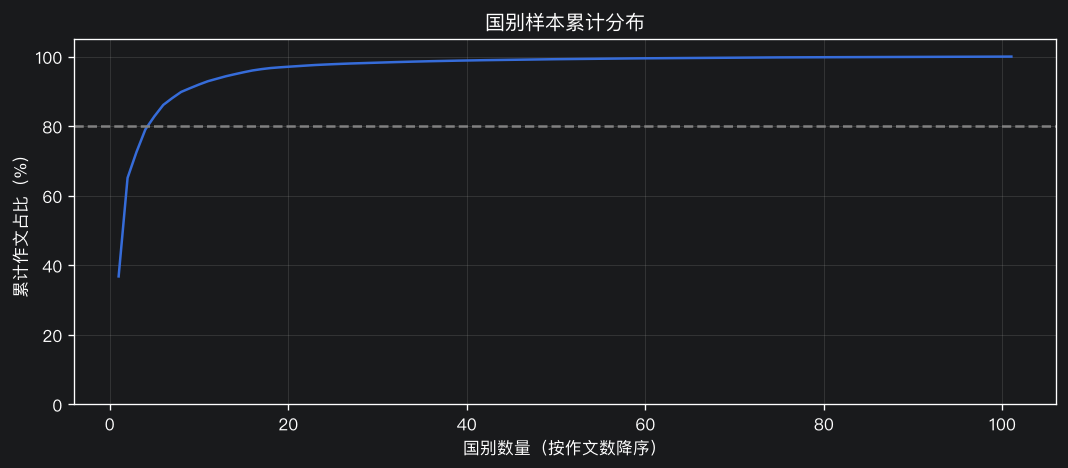

In [7]:
for k in [3, 5, 10, 20]:
    print(f'前{min(k,len(stats))}个国别作文占比：{stats["作文占比"].head(k).sum():.2%}')
for p in [0.5, 0.8, 0.9]:
    count = np.searchsorted(stats['作文累计占比'].to_numpy(), p) + 1
    print(f'覆盖{p:.0%}作文需要 {count} 个国别')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(stats)+1), stats['作文累计占比']*100)
ax.axhline(80, linestyle='--', color='gray')
ax.set(xlabel='国别数量（按作文数降序）', ylabel='累计作文占比（%）', title='国别样本累计分布', ylim=(0, 105))
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(output / 'cumulative_essay_share.png', dpi=160)
plt.show()

## 6. 篇均错句记录数分析
检索数据中的篇均记录数量（不代表真实偏误率），小样本国家波动较大。

,作文数,错句记录数,篇均错句记录数
国籍,,,
韩国,4169,59670,14.31
日本,3211,46967,14.63
新加坡,843,11126,13.20
印度尼西亚,739,8545,11.56
马来西亚,422,5892,13.96
泰国,374,3979,10.64
越南,221,2541,11.50
缅甸,202,2436,12.06
澳大利亚,123,1648,13.40


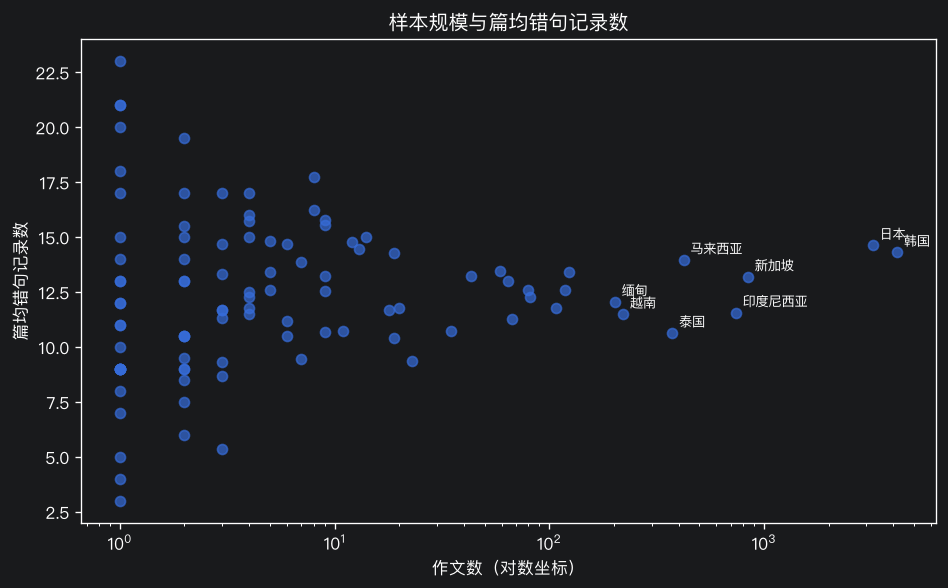

In [8]:
display(stats[['作文数','错句记录数','篇均错句记录数']].head(20).round(2))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(stats['作文数'], stats['篇均错句记录数'], alpha=.7)
ax.set(xscale='log', xlabel='作文数（对数坐标）', ylabel='篇均错句记录数', title='样本规模与篇均错句记录数')
for name, row in stats.head(8).iterrows():
    ax.annotate(name, (row['作文数'], row['篇均错句记录数']), xytext=(4,4), textcoords='offset points', fontsize=8)
fig.tight_layout()
fig.savefig(output / 'essay_size_vs_errors.png', dpi=160)
plt.show()

## 7. 候选研究国家筛选
使用多个作文数量阈值观察覆盖变化；核验重复记录对计数的影响。

In [9]:
thresholds = [30, 50, 100, 200, 500]
summary = pd.DataFrame([{'最低作文数': t, '国别数': int((stats['作文数'] >= t).sum()), '作文覆盖率': stats.loc[stats['作文数'] >= t, '作文占比'].sum()} for t in thresholds])
display(summary.style.format({'作文覆盖率':'{:.2%}'}))
MIN_ESSAYS = 100  # 根据实际分布调整
candidates = stats.loc[stats['作文数'] >= MIN_ESSAYS].copy()
display(candidates.round(4))
# 使用业务字段排除来源追踪字段后检查重复敏感性，不正式删除记录
business_cols = [col for col in sample.columns if col not in ['record_id','source_file','source_row']]
dedup = sample.drop_duplicates(subset=business_cols)
check = stats[['错句记录数','作文数']].join(dedup.groupby(country).size().rename('去重情景记录数'))
check['记录减少数'] = check['错句记录数'] - check['去重情景记录数']
display(check.sort_values('记录减少数', ascending=False).head(10))

,最低作文数,国别数,作文覆盖率
0,30,18,96.70%
1,50,16,96.01%
2,100,11,92.91%
3,200,8,89.83%
4,500,4,79.08%


,错句记录数,作文数,错句占比,作文占比,篇均错句记录数,作文累计占比
国籍,,,,,,
韩国,59670,4169,0.3834,0.3679,14.3128,0.3679
日本,46967,3211,0.3018,0.2833,14.6269,0.6512
新加坡,11126,843,0.0715,0.0744,13.1981,0.7256
印度尼西亚,8545,739,0.0549,0.0652,11.5629,0.7908
马来西亚,5892,422,0.0379,0.0372,13.9621,0.8280
泰国,3979,374,0.0256,0.0330,10.6390,0.8610
越南,2541,221,0.0163,0.0195,11.4977,0.8805
缅甸,2436,202,0.0157,0.0178,12.0594,0.8983
澳大利亚,1648,123,0.0106,0.0109,13.3984,0.9092


,错句记录数,作文数,去重情景记录数,记录减少数
国籍,,,,
韩国,59670,4169,59594,76
日本,46967,3211,46950,17
印度尼西亚,8545,739,8539,6
马来西亚,5892,422,5888,4
越南,2541,221,2538,3
圣马力诺,39,2,38,1
俄罗斯,992,81,991,1
英国,1273,108,1272,1
泰国,3979,374,3978,1


## 8. 分析结果导出

In [10]:
stats.to_csv(output / 'country_statistics.csv', encoding='utf-8-sig')
summary.to_csv(output / 'threshold_sensitivity.csv', index=False, encoding='utf-8-sig')
candidates.to_csv(output / 'candidate_countries.csv', encoding='utf-8-sig')
check.to_csv(output / 'duplicate_sensitivity.csv', encoding='utf-8-sig')

## 9. 国别样本分布分析结论

本次分析共涉及101个国别及地区取值、11,333篇作文及155,624条错句记录。语料库国别样本分布呈现显著的集中性与长尾特征，韩国、日本两国作文占比达到65.12%，作文数量排名前八位的东亚及东南亚国家累计占比达到89.84%。

以100篇作文为初步筛选阈值，共获得11个候选研究国家，覆盖92.91%的作文样本；以200篇为筛选阈值，仍可保留8个国家及89.84%的作文样本，表明现有语料具备开展部分国家间比较研究的样本基础。

主要国家的篇均错句记录数存在一定差异，但其形成原因尚不明确，需要结合考试时间、语言水平、作文题目等变量进一步分析。重复记录对总体国别样本分布的影响较小，暂不影响探索性分析的开展。

总体而言，现有语料不适合开展具有全球代表性的国别比较，但具备开展东亚、东南亚及部分其他国家学习者偏误比较研究的潜力。